In [1]:
import os

# Set the working directory
os.chdir('/home/jupyter/Alyssa/Single_Cell_CHIP_Vascular')

In [2]:
import scanpy
import anndata as ad
import numpy as np

In [2]:
print(scanpy.__version__)

1.9.3


In [3]:
mpp_data = ad.read_h5ad("rds_objects/pseudotime/mpp_no_sct.h5ad")

In [4]:
mpp_data.uns['iroot'] = np.flatnonzero(mpp_data.obs['cell_type'] == 'HSC')[0]

In [5]:
scanpy.pp.neighbors(mpp_data)

         Falling back to preprocessing with `sc.pp.pca` and default params.


/home/jupyter/.local/lib/python3.10/site-packages/umap/distances.py:1063: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/jupyter/.local/lib/python3.10/site-packages/umap/distances.py:1071: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/jupyter/.local/lib/python3.10/site-packages/umap/distances.py:1086: NumbaDeprecationWarning:

In [6]:
scanpy.tl.diffmap(mpp_data)
scanpy.tl.dpt(mpp_data)

In [3]:
import anndata
import numpy as np
import seaborn as sb
import numpy as np
import warnings
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from genes2genes import Main
from genes2genes import ClusterUtils
from genes2genes import TimeSeriesPreprocessor
from genes2genes import PathwayAnalyser
from genes2genes import VisualUtils

In [4]:
import genes2genes

In [6]:
print(sb.__version__)
print(genes2genes.__version__)

0.13.2
0.2.0


In [8]:
!python --version

Python 3.10.12


In [9]:
# Create a new AnnData object for 'tet2'
mpp_data_tet2 = mpp_data[mpp_data.obs['CRISPR_target'] == 'TET2'].copy()

# Create a new AnnData object for 'aavs'
mpp_data_aavs = mpp_data[mpp_data.obs['CRISPR_target'] == 'AAVS'].copy()

In [10]:
print(min(mpp_data_aavs.obs['dpt_pseudotime']), max(mpp_data_aavs.obs['dpt_pseudotime']))
print(min(mpp_data_tet2.obs['dpt_pseudotime']), max(mpp_data_tet2.obs['dpt_pseudotime']))

0.0 0.9757195115089417
0.015590846538543701 1.0


In [12]:
os.makedirs('figures/pseudotime', exist_ok=True)

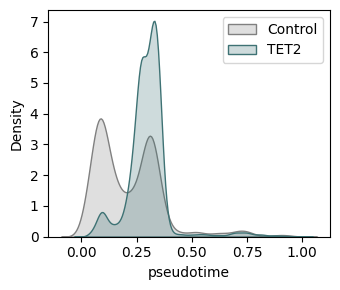

In [25]:
# Visualize the pseudotime distributions
plt.figure(figsize = (3.5,3))
sb.kdeplot(mpp_data_aavs.obs['dpt_pseudotime'], fill=True, label='Control', color='grey') 
sb.kdeplot(mpp_data_tet2.obs['dpt_pseudotime'], fill=True, label='TET2', color='#3E7274') 
plt.xlabel('pseudotime'); plt.legend()
plt.tight_layout()
plt.savefig('figures/pseudotime/overall_pseudotime.svg', dpi = 600)
plt.show()

In [26]:
from optbinning import ContinuousOptimalBinning

x = np.asarray(mpp_data_aavs.obs.dpt_pseudotime)
optb = ContinuousOptimalBinning(name='pseudotime', dtype="numerical")
optb.fit(x, x)
print(len(optb.splits))

x = np.asarray(mpp_data_tet2.obs.dpt_pseudotime)
optb = ContinuousOptimalBinning(name='pseudotime', dtype="numerical")
optb.fit(x, x)
print(len(optb.splits))

(CVXPY) Feb 12 03:46:45 PM: Encountered unexpected exception importing solver GLOP:
RuntimeError('Unrecognized new version of ortools (9.11.4210). Expected < 9.5.0.Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Feb 12 03:46:45 PM: Encountered unexpected exception importing solver PDLP:
RuntimeError('Unrecognized new version of ortools (9.11.4210). Expected < 9.5.0.Please open a feature request on cvxpy to enable support for this version.')
14
15


In [27]:
n_bins = 15

In [28]:
mpp_data_aavs.obs['time'] = mpp_data_aavs.obs['dpt_pseudotime']
mpp_data_tet2.obs['time'] = mpp_data_tet2.obs['dpt_pseudotime']

In [29]:
def plot_pseudotime_dists_with_interpolation_points(adata_ref, adata_query, n_bins):

    plt.figure(figsize=(4,3))
    sb.kdeplot(adata_ref.obs.time, fill=True, color='grey')
    sb.kdeplot(adata_query.obs.time, fill=True, color='#3E7274')
    vlines = np.linspace(0,1,n_bins)
    for v in vlines:
        plt.axvline(x=v, color='black', linewidth=1)
    plt.xlim([0,1])
    plt.title('Interpolation points')

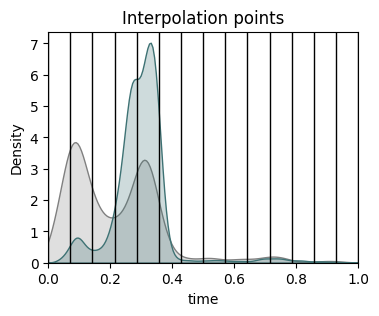

In [30]:
plot_pseudotime_dists_with_interpolation_points(mpp_data_aavs, mpp_data_tet2, n_bins)

In [31]:
np.array(sb.color_palette('colorblind'))


array([[0.0039215686, 0.4509803922, 0.6980392157],
       [0.8705882353, 0.5607843137, 0.0196078431],
       [0.0078431373, 0.6196078431, 0.4509803922],
       [0.8352941176, 0.368627451 , 0.          ],
       [0.8         , 0.4705882353, 0.737254902 ],
       [0.7921568627, 0.568627451 , 0.3803921569],
       [0.9843137255, 0.6862745098, 0.8941176471],
       [0.5803921569, 0.5803921569, 0.5803921569],
       [0.9254901961, 0.8823529412, 0.2         ],
       [0.337254902 , 0.7058823529, 0.9137254902]])

In [32]:
# define the joint colormap to use for both reference and query
annotation_colname = "cell_type"
col = np.array(sb.color_palette('colorblind'))[range(10)]
joint_cmap={'MPP':col[0], 'HSC':col[1] , 'platelet':col[2] , 'ERP':col[3], 'EPC':col[4], 'LMPP':col[5] , 'neutrophil':col[6] , 'monocyte':col[7], 'GMP':col[8] , 'dendritic':col[9] , 'MEP':'black'}

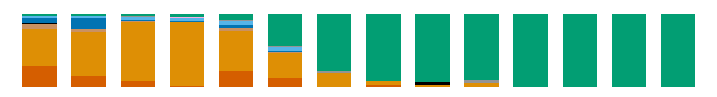

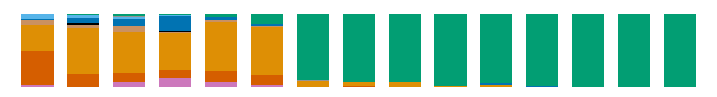

In [33]:
VisualUtils.plot_celltype_barplot(mpp_data_aavs, n_bins, annotation_colname, joint_cmap)
VisualUtils.plot_celltype_barplot(mpp_data_tet2, n_bins, annotation_colname, joint_cmap)

In [34]:
# define the gene list to align
#gene_list = ["GATA1", "MYC", "SP1", "NFE2", "HDAC1", "TAF1", "MYB", "TBP", "LMO2", "TBP", "LMO2", "TAL1", "MED1", "KMT2D", "GATA2", "JUN", "IRF1", "CEBPA", "ETV6"]
gene_list = ["NOTCH1", "CTNNB1", "ZEB1", "VEZF1", "ETV2"]
print(len(gene_list),'genes')

5 genes


In [94]:
## Transcription factors identified from here: https://academic.oup.com/nar/article/51/20/10934/7318114
#import pandas as pd

## Load the CSV file
#file_path = 'input_data/CollecTRI_regulons.csv'
#tf_df = pd.read_csv(file_path)

## Get unique values from the 'source' column
#tfs = tf_df['source'].unique()

## Print the unique values
#print(tfs)

#gene_list = [value for value in tfs if value in mpp_data_aavs.var['features'].tolist()]

['MYC' 'SPI1' 'SMAD3' ... 'TLE4' 'AP1' 'NFKB']


In [35]:
aligner = Main.RefQueryAligner(mpp_data_aavs, mpp_data_tet2, gene_list, n_bins)
aligner.align_all_pairs() 

Genes2Genes (v0.2.0)
Dynamic programming alignment of gene pseudotime trajectories using a bayesian information-theoretic framework
Interpolator initialization completed
Aligner initialised to align trajectories of 3385 reference cells & 10423 query cells in terms of 5 genes
Running gene-level alignment: 🧬


100%|██████████| 5/5 [00:04<00:00,  1.03it/s]

Alignment completed! ✅


In [106]:
#import pickle

# Save an object to a file
#with open('rds_objects/pseudotime/aligner.pkl', 'wb') as file:
#    pickle.dump(aligner, file)
#with open('rds_objects/pseudotime/mpp_data_aavs.pkl', 'wb') as file:
#    pickle.dump(mpp_data_aavs, file)
#with open('rds_objects/pseudotime/mpp_data_tet2.pkl', 'wb') as file:
#    pickle.dump(mpp_data_tet2, file)

In [5]:
import pickle

# Load aligner
with open('rds_objects/pseudotime/aligner.pkl', 'rb') as file:
    aligner = pickle.load(file)


MMMMMMMIDIDIIIIIIDDDDDD
MMMMMMMIDIDIIIIIIDDDDDD

01234567890123456789012 Alignment index 
0123456 7 8      901234 Reference index
*******-*-*------******
********-*-******------
01234567 8 901234       Query index
MMMMMMMIDIDIIIIIIDDDDDD 5-state string 


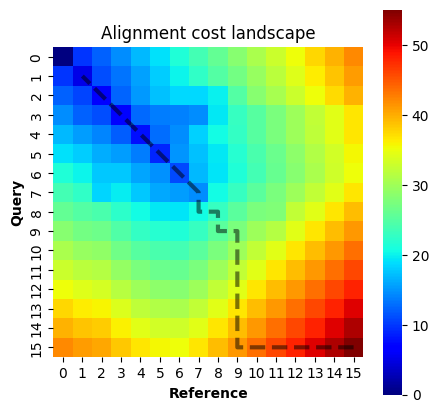

In [22]:
gene_obj = aligner.results_map['NOTCH1']
alignment_str = gene_obj.alignment_str
print(alignment_str)
print(VisualUtils.color_al_str(alignment_str)) 
print()
print(gene_obj.al_visual)
# Alignment landscape of costs (Note: dashed black path is the optimal alignment)
gene_obj.landscape_obj.plot_alignment_landscape()
# Note: optimal path diagonals represent matches; 
# vertical and horizontal paths could represent either warp matches or indels (mismatches)

In [6]:
def plotTimeSeriesAlignment(gene, aligner):
    
        plt.figure(figsize = (3,3.5))
        al_obj = aligner.results_map[gene]
        sb.scatterplot(x=al_obj.S.X, y=al_obj.S.Y, color = 'grey' ,alpha=1, legend=False, label='Control') 
        sb.scatterplot(x=al_obj.T.X, y=al_obj.T.Y, color = '#3E7274' ,alpha=1, legend=False, label ='TET2') 
        al_obj.S.plot_mean_trend(color='grey')
        al_obj.T.plot_mean_trend(color='#3E7274')
        plt.title(al_obj.gene)
        plt.xlabel('Pseudotime')
        plt.ylabel('Gene expression')
        
        for i in range(al_obj.matched_region_DE_info.shape[0]):
            S_timebin = int(al_obj.matched_region_DE_info.iloc[i]['ref_bin'])
            T_timebin = int(al_obj.matched_region_DE_info.iloc[i]['query_bin']) 
            x_vals = [al_obj.matched_region_DE_info.iloc[i]['ref_pseudotime'],al_obj.matched_region_DE_info.iloc[i]['query_pseudotime']] 
            y_vals = [al_obj.S.mean_trend[S_timebin ], al_obj.T.mean_trend[T_timebin]] 
            plt.plot(x_vals, y_vals, color='black', linestyle='dashed', linewidth=1.5)
        
        plt.tight_layout()
        plt.savefig(f"figures/pseudotime/{gene}_pseudotime.svg",  dpi = 600)

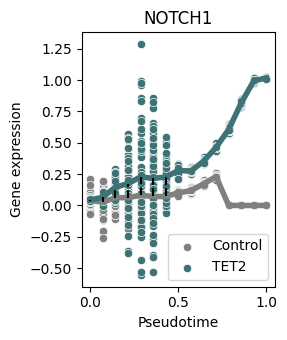

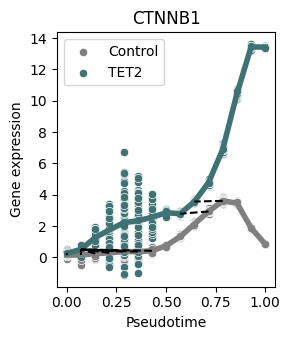

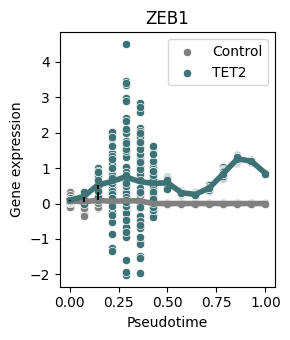

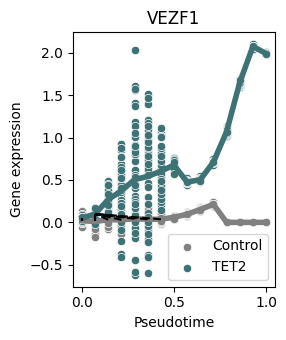

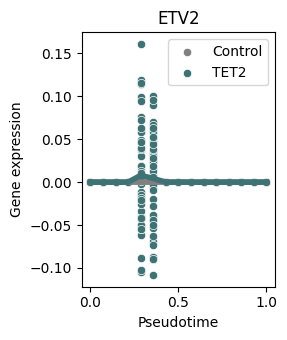

In [7]:
plotTimeSeriesAlignment('NOTCH1', aligner)
plotTimeSeriesAlignment('CTNNB1', aligner)
plotTimeSeriesAlignment('ZEB1', aligner)
plotTimeSeriesAlignment('VEZF1', aligner)
plotTimeSeriesAlignment('ETV2', aligner)

MMMMMMMIDIDIIIIIIDDDDDD
Optimal alignment cost: 55.141 nits
Alignment similarity percentage: 30.43 %


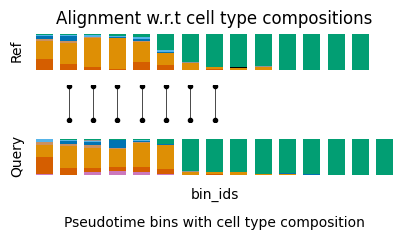

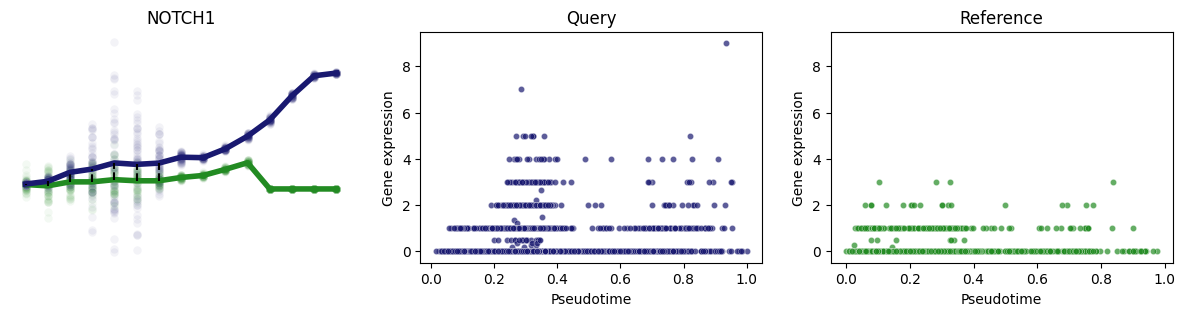

In [23]:
VisualUtils.show_gene_alignment('NOTCH1', aligner, mpp_data_aavs, mpp_data_tet2, annotation_colname, joint_cmap)

MMWWWWWIIIDIDIDIMMIIIIIDDD
Optimal alignment cost: 57.451 nits
Alignment similarity percentage: 34.62 %


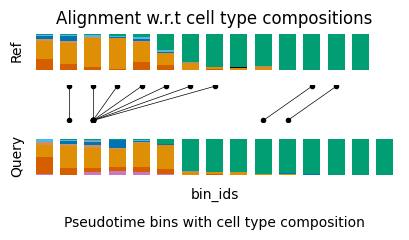

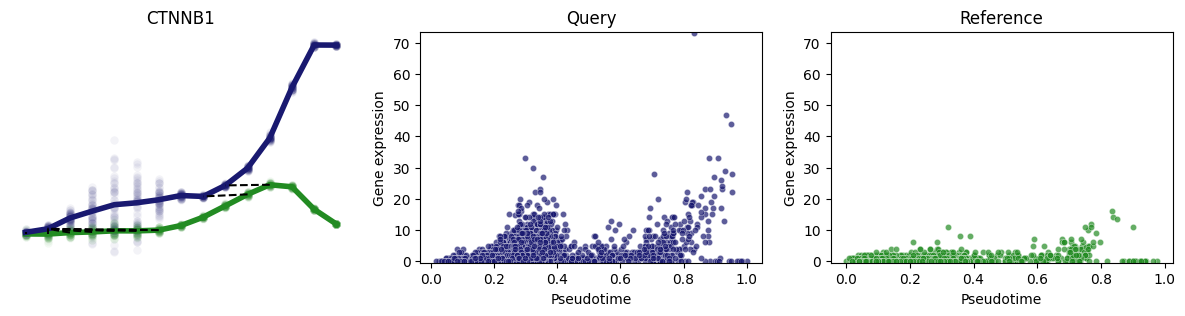

In [24]:
VisualUtils.show_gene_alignment('CTNNB1', aligner, mpp_data_aavs, mpp_data_tet2, annotation_colname, joint_cmap)

MMMIIIIIDIDIDIIIIIDDDDDDDDD
Optimal alignment cost: 63.514 nits
Alignment similarity percentage: 11.11 %


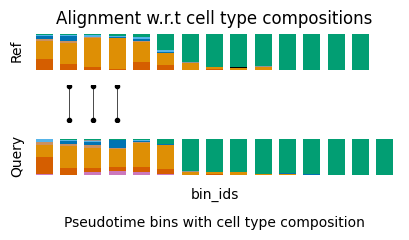

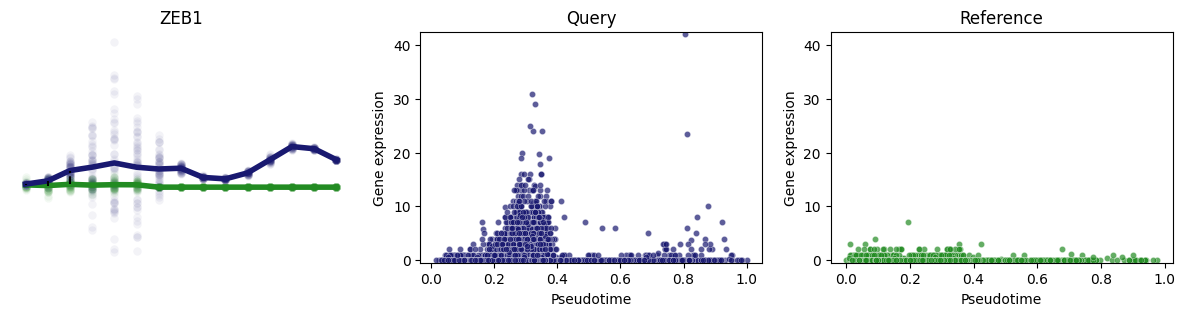

In [25]:
VisualUtils.show_gene_alignment('ZEB1', aligner, mpp_data_aavs, mpp_data_tet2, annotation_colname, joint_cmap)

MMWWWWWIDIDIDIIIIIIIIIIDDDDD
Optimal alignment cost: 62.482 nits
Alignment similarity percentage: 25.0 %


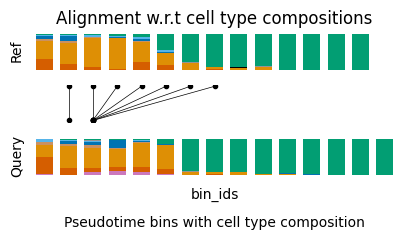

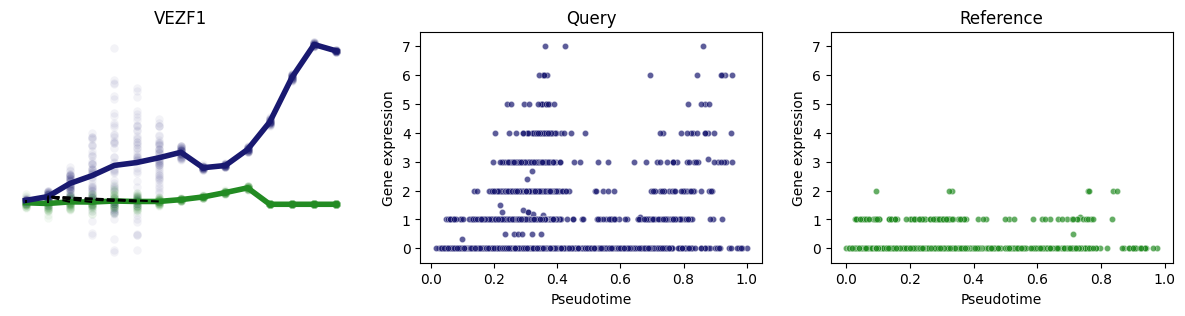

In [26]:
VisualUtils.show_gene_alignment('VEZF1', aligner, mpp_data_aavs, mpp_data_tet2, annotation_colname, joint_cmap)

MMMMIIDDMMMMMMMMM
Optimal alignment cost: 10.951 nits
Alignment similarity percentage: 76.47 %


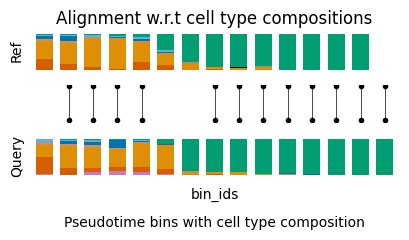

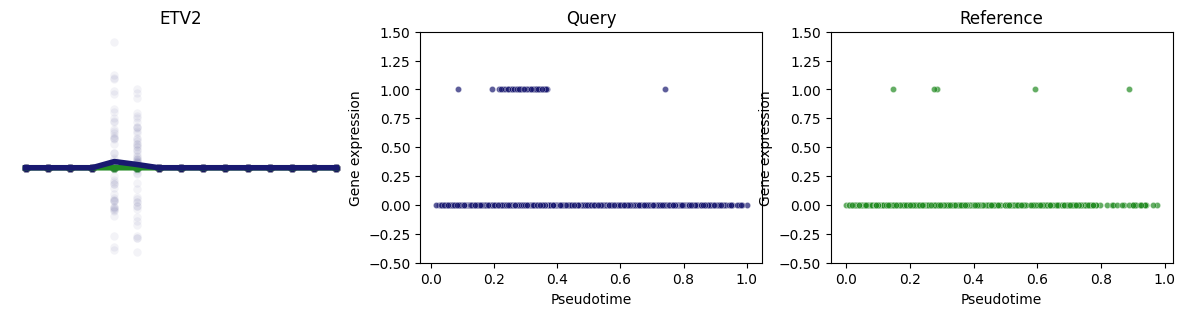

In [27]:
VisualUtils.show_gene_alignment('ZEB1', aligner, mpp_data_aavs, mpp_data_tet2, annotation_colname, joint_cmap)

Average Alignment:  MMMIIIDDDMIDIDIIIIIIDDDDDD (cell-level)
% similarity: 15.38


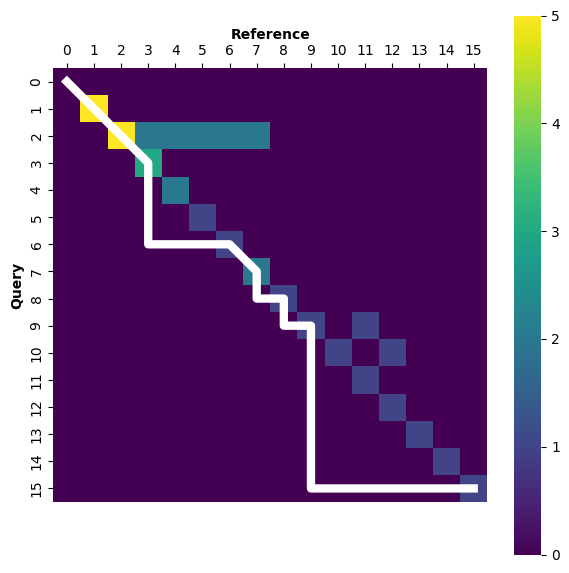

In [28]:
aligner.get_aggregate_alignment() 
# Note: White path represents the average alignment path where diagonals represent matches; 
# vertical and horizontal paths could represent either warp matches or indels (mismatches)

Mean alignment similarity percentage (matched %): 
35.53 %


,Gene,alignment_similarity_percentage,opt_alignment_cost,l2fc,color,abs_l2fc
2,ZEB1,0.1111,63.513765,-3.138935,red,3.138935
3,VEZF1,0.25,62.482099,-3.697953,red,3.697953
0,NOTCH1,0.3043,55.141165,-1.697035,red,1.697035
1,CTNNB1,0.3462,57.450721,-2.555615,red,2.555615
4,ETV2,0.7647,10.95071,-2.032809,green,2.032809


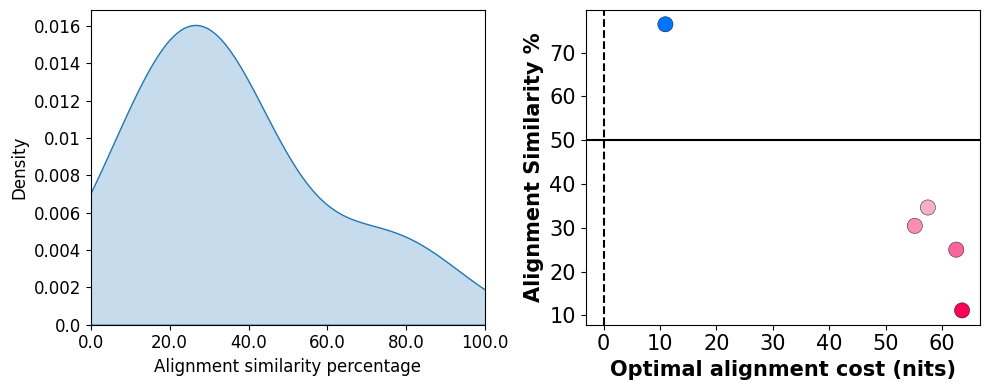

In [29]:
df = aligner.get_stat_df() # ordered genes according to alignment similarity statistics 
df

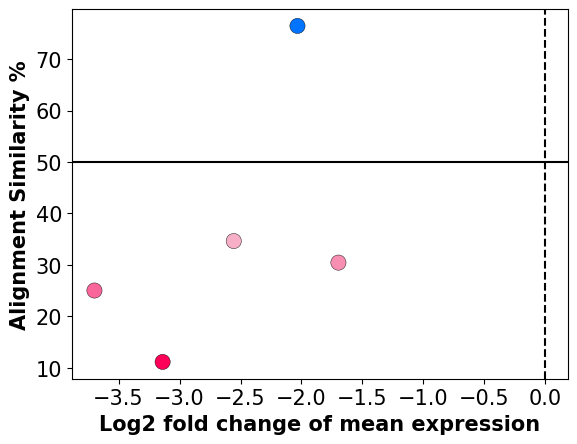

In [30]:
VisualUtils.plot_alignmentSim_vs_l2fc(df)

In [31]:
earliest_match_sorted_genes_list = aligner.show_ordered_alignments() 


In the order of the first match occurrence along pseudotime
Gene    Alignment
------  ----------------------------
NOTCH1  MMMMMMMIDIDIIIIIIDDDDDD
CTNNB1  MMWWWWWIIIDIDIDIMMIIIIIDDD
VEZF1   MMWWWWWIDIDIDIIIIIIIIIIDDDDD
ETV2    MMMMIIDDMMMMMMMMM
ZEB1    MMMIIIIIDIDIDIIIIIDDDDDDDDD


In [32]:
threshold_similarity = 0.3 
topDEgenes = df[list(df['alignment_similarity_percentage'] <=threshold_similarity)]['Gene']
# Calling wrapper function for GSEAPy enrichr inferface
pathway_df = PathwayAnalyser.run_overrepresentation_analysis(topDEgenes) 
pathway_df.head(5)

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes,-log10 Adjusted P-value,-log10 FDR q-val
0,MSigDB_Hallmark_2020,Complement,1/200,0.019900,0.019900,0,0,99.492462,389.713783,ZEB1,1.701139,1.701139
1,MSigDB_Hallmark_2020,heme Metabolism,1/200,0.019900,0.019900,0,0,99.492462,389.713783,VEZF1,1.701139,1.701139
2,KEGG_2021_Human,Prostate cancer,1/97,0.009677,0.028662,0,0,207.312500,961.524242,ZEB1,1.542690,1.542690
3,KEGG_2021_Human,Transcriptional misregulation in cancer,1/192,0.019108,0.028662,0,0,103.701571,410.413414,ZEB1,1.542690,1.542690
4,KEGG_2021_Human,MicroRNAs in cancer,1/310,0.030760,0.030760,0,0,63.718447,221.837650,ZEB1,1.512009,1.512009
